# Análise de Séries Temporais

Datas, agregações, janelas móveis, indicadores e exercícios resolvidos.

Os exemplos usam arquivos pequenos da pasta `datasets/` e podem ser executados na ordem. Exercícios resolvidos aparecem junto dos respectivos enunciados.

**Objetivo:** distinguir série observada de frequência presumida, escolher agregações compatíveis com cada métrica e interpretar janelas incompletas.

### Materiais complementares

- [Guia — Séries temporais](./reference_materials/04_analise_de_series_temporais.pdf)
- [Cheat sheet — Séries temporais](./cheat_sheets/cheat_sheet_series_temporais.pdf)

Os arquivos estão nesta mesma pasta da disciplina. Os PDFs complementam, mas não substituem, a execução das células.

## 1. Datas e frequência

Séries temporais precisam de datas válidas, periodicidade definida, ordenação e compreensão de ausências. O dataset simula 180 dias de condições meteorológicas.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

def preparar_pastas():
    """Localiza a biblioteca e cria as pastas de dados e resultados, se ausentes."""
    atual = Path.cwd().resolve()
    # Aceita execução na raiz da biblioteca ou em uma pasta filha.
    candidatos = [atual, atual.parent]
    raiz = next(
        (p for p in candidatos if (p / 'vendas_exemplo.csv').is_file() or
         (p / 'datasets' / 'vendas_exemplo.csv').is_file()),
        None,
    )
    if raiz is None:
        # Identifica a raiz da biblioteca pelo conjunto de notebooks.
        raiz = next(
            (p for p in candidatos if (p / '01_Analise_Exploratoria_de_Dados.ipynb').is_file()),
            atual,
        )
    dados = raiz / 'datasets'
    saidas = raiz / 'outputs'
    dados.mkdir(parents=True, exist_ok=True)
    saidas.mkdir(parents=True, exist_ok=True)
    return dados, saidas

DATA, OUTPUTS = preparar_pastas()

def conferir_datasets(*nomes):
    ausentes = [nome for nome in nomes if not (DATA / nome).is_file()]
    if ausentes:
        raise FileNotFoundError(
            'Datasets ausentes: ' + ', '.join(ausentes) + '\n'
            + 'Coloque os CSVs fornecidos em: ' + str(DATA.resolve()) + '\n'
            + 'Criar a pasta datasets/ não cria automaticamente os arquivos CSV.'
        )
conferir_datasets('clima_sintetico.csv')
clima=pd.read_csv(DATA/'clima_sintetico.csv',parse_dates=['data']).sort_values('data').set_index('data')
print(clima.head(3))
print('Início:',clima.index.min(),'| fim:',clima.index.max())

            temperatura_c  umidade_pct  chuva_mm
data                                            
2024-01-01           21.2         58.3       0.0
2024-01-02           22.2         69.5       5.9
2024-01-03           24.6         62.9       0.0
Início: 2024-01-01 00:00:00 | fim: 2024-06-28 00:00:00


## 2. Reamostragem e agregação

Uma temperatura diária pode ser agregada por média mensal; para chuva, frequentemente interessa somar o acumulado. A escolha deve refletir a unidade e a natureza da variável.

**Atenção:** meses parciais podem produzir totais de chuva menores simplesmente por conterem menos dias observados. Para comparações justas, apresente também a cobertura temporal e, quando necessário, a média diária de chuva observada.

In [2]:
mensal=clima.resample('MS').agg(temperatura_media_c=('temperatura_c','mean'),chuva_total_mm=('chuva_mm','sum'),umidade_media_pct=('umidade_pct','mean'))
print(mensal.round(2))
cobertura = clima['chuva_mm'].resample('MS').agg(dias_observados='count', media_diaria_mm='mean')
cobertura['dias_no_mes'] = cobertura.index.days_in_month
cobertura['cobertura_pct'] = 100 * cobertura['dias_observados'] / cobertura['dias_no_mes']
print('Cobertura mensal (meses parciais exigem cautela):\n', cobertura.round(1))

            temperatura_media_c  chuva_total_mm  umidade_media_pct
data                                                              
2024-01-01                22.21            59.4              69.23
2024-02-01                21.87            45.5              68.77
2024-03-01                21.45            42.6              70.87
2024-04-01                22.05            56.8              71.84
2024-05-01                21.77            49.7              69.95
2024-06-01                22.52            35.5              70.42
Cobertura mensal (meses parciais exigem cautela):
             dias_observados  media_diaria_mm  dias_no_mes  cobertura_pct
data                                                                    
2024-01-01               31              1.9           31          100.0
2024-02-01               29              1.6           29          100.0
2024-03-01               31              1.4           31          100.0
2024-04-01               30              1.9    

## 3. Médias móveis e comparação com valores originais

Uma média móvel suaviza oscilações, mas não é previsão. O parâmetro `min_periods` determina quando o cálculo começa.

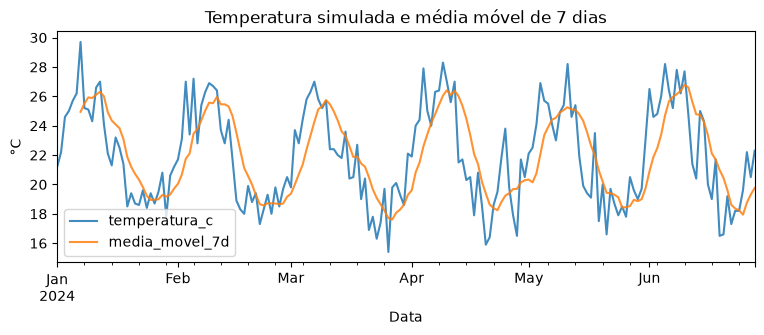

In [3]:
import matplotlib.pyplot as plt
clima['media_movel_7d']=clima['temperatura_c'].rolling(7,min_periods=7).mean()
ax=clima[['temperatura_c','media_movel_7d']].plot(figsize=(9,3),alpha=.85)
ax.set(title='Temperatura simulada e média móvel de 7 dias',ylabel='°C',xlabel='Data')
plt.show()

## 4. Diferenças, crescimento e dados faltantes

`diff()` calcula a diferença entre períodos; `pct_change()` calcula variações relativas. Em séries acumuladas, aplique `diff()` apenas após confirmar a consistência do acumulado e possíveis correções retroativas.

**Nota de versão:** para variação percentual use `pct_change(fill_method=None)` quando necessário, evitando preenchimento implícito em versões antigas do Pandas. Uma porcentagem tem unidade diferente de diferença absoluta.

In [4]:
clima['variacao_diaria_c']=clima['temperatura_c'].diff()
print(clima[['temperatura_c','variacao_diaria_c']].head())
print('Dias ausentes no índice:',len(pd.date_range(clima.index.min(),clima.index.max(),freq='D').difference(clima.index)))

            temperatura_c  variacao_diaria_c
data                                        
2024-01-01           21.2                NaN
2024-01-02           22.2                1.0
2024-01-03           24.6                2.4
2024-01-04           25.0                0.4
2024-01-05           25.7                0.7
Dias ausentes no índice: 0


## 5. Exercício resolvido — maior volume mensal de chuva

**Enunciado:** encontre o mês com maior precipitação acumulada e informe o total.

In [5]:
mes_mais_chuvoso=mensal['chuva_total_mm'].idxmax()
print(mes_mais_chuvoso.strftime('%Y-%m'),round(mensal.loc[mes_mais_chuvoso,'chuva_total_mm'],1),'mm')

2024-01 59.4 mm


## 6. Exercício resolvido — mudança entre dois meses

**Enunciado:** calcule a diferença de temperatura média entre o primeiro e o segundo mês disponível.

In [6]:
mudanca=mensal['temperatura_media_c'].iloc[1]-mensal['temperatura_media_c'].iloc[0]
print('Diferença entre as médias:',round(mudanca,2),'°C')

Diferença entre as médias: -0.34 °C


## 7. Frequências irregulares e datas ausentes
Uma sequência diária pode conter dias sem observação. `asfreq('D')` revela lacunas; não preencha automaticamente com zero, pois ausência de observação e valor zero são conceitos diferentes.

In [7]:
serie_irregular = clima['temperatura_c'].iloc[::3].copy()
grade_diaria = serie_irregular.asfreq('D')
print('Datas não observadas após regularização:', int(grade_diaria.isna().sum()))
print('Primeiras datas disponíveis:', grade_diaria.head(8).to_string())
# Interpolação é apenas exemplo didático e não representa medição real.
interpolada = grade_diaria.interpolate(method='time', limit=2)
assert interpolada.notna().sum() >= grade_diaria.notna().sum()

Datas não observadas após regularização: 118
Primeiras datas disponíveis: data
2024-01-01    21.2
2024-01-02     NaN
2024-01-03     NaN
2024-01-04    25.0
2024-01-05     NaN
2024-01-06     NaN
2024-01-07    29.7
2024-01-08     NaN
Freq: D


## 8. Reamostragem por tipo de variável e médias móveis
Use média para temperatura, soma para precipitação e **último valor** para indicadores acumulados. Compare janelas móveis com números diferentes de observações para enxergar o efeito de suavização.

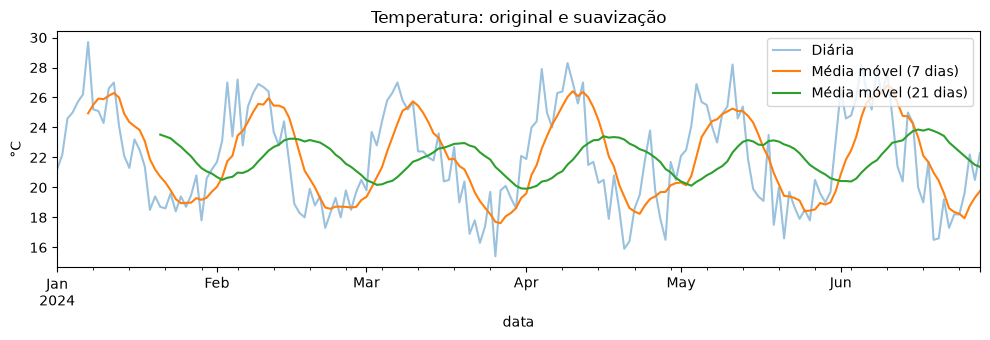

            temperatura_media  chuva_total
data                                      
2024-01-07              24.94         14.0
2024-01-14              24.91         21.5
2024-01-21              20.71          6.9
2024-01-28              19.29         11.5
2024-02-04              22.11         27.3


In [8]:
semanal = clima.resample('W').agg(temperatura_media=('temperatura_c','mean'), chuva_total=('chuva_mm','sum'))
fig, ax = plt.subplots(figsize=(10, 3.5))
clima['temperatura_c'].plot(ax=ax, label='Diária', alpha=.45)
clima['temperatura_c'].rolling(window=7, min_periods=7).mean().plot(ax=ax, label='Média móvel (7 dias)')
clima['temperatura_c'].rolling(window=21, min_periods=21).mean().plot(ax=ax, label='Média móvel (21 dias)')
ax.set(title='Temperatura: original e suavização', ylabel='°C');ax.legend()
fig.tight_layout();plt.show()
print(semanal.head().round(2))

## 9. Acumulado versus variação por período
Diferenças de um acumulado só representam novas ocorrências quando a métrica é consistente e não sofre revisões. Valores negativos podem indicar correções retroativas.

In [9]:
exemplo_acumulado = pd.Series([10, 15, 22, 22, 30], index=pd.date_range('2024-01-01',periods=5))
novos = exemplo_acumulado.diff().fillna(exemplo_acumulado.iloc[0])
print(pd.DataFrame({'acumulado': exemplo_acumulado, 'novos': novos}).to_string())
assert novos.sum() == exemplo_acumulado.iloc[-1]

            acumulado  novos
2024-01-01         10   10.0
2024-01-02         15    5.0
2024-01-03         22    7.0
2024-01-04         22    0.0
2024-01-05         30    8.0


## 10. Exercício resolvido — mês mais quente e mês mais chuvoso
**Enunciado:** produza indicadores mensais distintos: média de temperatura e soma de chuva. Compare os meses extremos e explique por que essas agregações não são intercambiáveis.

In [10]:
clima_mensal = clima.resample('MS').agg(temp_media=('temperatura_c','mean'), chuva_total=('chuva_mm','sum'))
mais_quente = clima_mensal['temp_media'].idxmax()
mais_chuvoso = clima_mensal['chuva_total'].idxmax()
print('Mês mais quente:', mais_quente.strftime('%Y-%m'), '|', round(clima_mensal.loc[mais_quente,'temp_media'], 1), '°C')
print('Mês mais chuvoso:', mais_chuvoso.strftime('%Y-%m'), '|', round(clima_mensal.loc[mais_chuvoso,'chuva_total'], 1), 'mm')
assert len(clima_mensal) >= 2

Mês mais quente: 2024-06 | 22.5 °C
Mês mais chuvoso: 2024-01 | 59.4 mm


### Cuidados temporais
Ordene e valide datas; documente o fuso horário; escolha frequência explicitamente; evite médias móveis que misturem periodicidades; diferencie ausência de registro e zero real.

## 11. Exercício resolvido — qualidade temporal e comparação de meses

**Enunciado:** identifique períodos com cobertura inferior a 100%, confronte o mês de maior chuva total com a média diária observada e verifique se o índice está em ordem e sem duplicações.

**Solução:** a cobertura depende dos dias efetivamente observados, não apenas dos valores acumulados. Sem observar o mês inteiro, não podemos afirmar que o total é comparável ao de meses completos.

In [11]:
assert clima.index.is_monotonic_increasing
assert not clima.index.has_duplicates
meses_parciais = cobertura.loc[cobertura['cobertura_pct'] < 100]
print('Meses com cobertura incompleta:')
print(meses_parciais[['dias_observados', 'dias_no_mes', 'cobertura_pct']].round(1))
print('Maior chuva total conhecida:', mensal['chuva_total_mm'].idxmax().strftime('%Y-%m'))
print('Maior média diária observada:', cobertura['media_diaria_mm'].idxmax().strftime('%Y-%m'))
assert (cobertura['cobertura_pct'] <= 100).all()

Meses com cobertura incompleta:
            dias_observados  dias_no_mes  cobertura_pct
data                                                   
2024-06-01               28           30           93.3
Maior chuva total conhecida: 2024-01
Maior média diária observada: 2024-01


### Interpretação e limitações

- Para um total mensal, conte dias faltantes antes de comparar meses.
- `rolling(7)` usa sete **observações**, não necessariamente sete dias corridos em uma série irregular; `rolling('7D')` usa intervalo temporal em índice compatível.
- Uma janela móvel suaviza variações e pode atrasar visualmente os picos; não equivale a previsão.
- A interpolação é uma aproximação e não deve ser confundida com uma medição.

## Consulta rápida

| Objetivo | Método |
|---|---|
| Converter datas | `pd.to_datetime` |
| Organizar índice | `.set_index('data').sort_index()` |
| Agrupar por período | `.resample('MS').agg(...)` |
| Suavizar | `.rolling(window).mean()` |
| Diferenças | `.diff()` |
| Detectar lacunas | `date_range(...).difference(index)` |

Lembre-se de documentar fuso horário, frequência, periodicidade e agregação.
| Cobertura por mês | `resample('MS').count()` comparado a `index.days_in_month` |
| Janela de tempo | `.rolling('7D')` (índice temporal ordenado) |
| Taxa de variação | `.pct_change(fill_method=None)` |

## Aprofundamento v2 — calendário, frequência e cobertura temporal

A ausência de datas pode significar falha de coleta ou atividade igual a zero. **Não transforme datas ausentes em zeros automaticamente.** Para séries de vendas, a soma e a média respondem perguntas distintas e devem ser identificadas.

**Exercício resolvido:** identificar dias sem observações sem inventar valores para eles.

In [12]:
import pandas as pd
exemplo_tempo_v2 = pd.DataFrame({'data':pd.to_datetime(['2026-01-01','2026-01-03']), 'valor':[10,20]})
calendario_v2 = pd.date_range(exemplo_tempo_v2['data'].min(),exemplo_tempo_v2['data'].max(),freq='D')
serie_v2 = exemplo_tempo_v2.set_index('data')['valor'].reindex(calendario_v2)
assert serie_v2.isna().sum() == 1
assert pd.isna(serie_v2.loc['2026-01-02'])
print('Datas sem registro:',serie_v2[serie_v2.isna()].index.strftime('%Y-%m-%d').tolist())
print('Cobertura de dias observados:',f'{serie_v2.notna().mean():.1%}')

Datas sem registro: ['2026-01-02']
Cobertura de dias observados: 66.7%


**Cuidados adicionais:** explicitar timezone e horário de verão quando houver timestamps; separar comparação sazonal de tendência; verificar efeitos de agregações semanais e mensais.